In [2]:
import numpy as np
import pandas as pd

In [3]:
df=pd.read_csv('titanic.csv')

In [4]:
df.head()

,Cabin,Ticket,number,Survived
0,NaN,A/5 21171,5,0
1,C85,PC 17599,3,1
2,NaN,STON/O2. 3101282,6,1
3,C123,113803,3,1
4,NaN,373450,A,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Cabin     204 non-null    object
 1   Ticket    891 non-null    object
 2   number    891 non-null    object
 3   Survived  891 non-null    int64 
dtypes: int64(1), object(3)
memory usage: 28.0+ KB


In [9]:
df.dtypes

Cabin       object
Ticket      object
number      object
Survived     int64
dtype: object

In [7]:
df.isnull().sum()

Cabin       687
Ticket        0
number        0
Survived      0
dtype: int64

In [8]:
df.duplicated().sum()

24

<Axes: xlabel='number'>

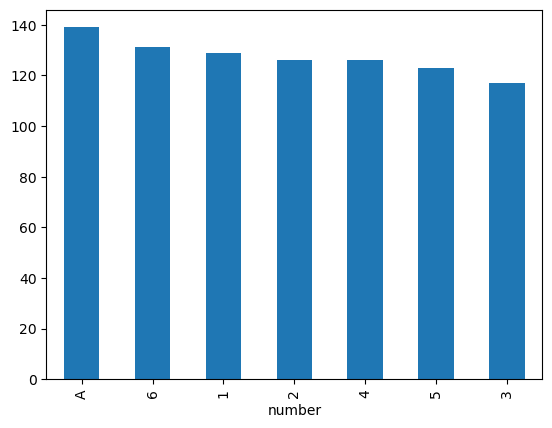

In [11]:
df['number'].value_counts().plot.bar()

In [12]:
df['number'].unique()

array(['5', '3', '6', 'A', '2', '1', '4'], dtype=object)

In [15]:
# extract numerical part
df['number_numerical'] = pd.to_numeric(df["number"],errors='coerce',downcast='integer')
df.head()

,Cabin,Ticket,number,Survived,number_numerical
0,NaN,A/5 21171,5,0,5.0
1,C85,PC 17599,3,1,3.0
2,NaN,STON/O2. 3101282,6,1,6.0
3,C123,113803,3,1,3.0
4,NaN,373450,A,0,NaN


In [16]:
df.dtypes

Cabin                object
Ticket               object
number               object
Survived              int64
number_numerical    float64
dtype: object

In [34]:
# extract categorical part
df['number_categorical'] = np.where(df['number_numerical'].isnull(),df['number'],np.nan)

df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical
0,NaN,A/5 21171,5,0,5.0,NaN
1,C85,PC 17599,3,1,3.0,NaN
2,NaN,STON/O2. 3101282,6,1,6.0,NaN
3,C123,113803,3,1,3.0,NaN
4,NaN,373450,A,0,NaN,A


In [35]:
df['Cabin'].unique()

array([nan, 'C85', 'C123', 'E46', 'G6', 'C103', 'D56', 'A6',
       'C23 C25 C27', 'B78', 'D33', 'B30', 'C52', 'B28', 'C83', 'F33',
       'F G73', 'E31', 'A5', 'D10 D12', 'D26', 'C110', 'B58 B60', 'E101',
       'F E69', 'D47', 'B86', 'F2', 'C2', 'E33', 'B19', 'A7', 'C49', 'F4',
       'A32', 'B4', 'B80', 'A31', 'D36', 'D15', 'C93', 'C78', 'D35',
       'C87', 'B77', 'E67', 'B94', 'C125', 'C99', 'C118', 'D7', 'A19',
       'B49', 'D', 'C22 C26', 'C106', 'C65', 'E36', 'C54',
       'B57 B59 B63 B66', 'C7', 'E34', 'C32', 'B18', 'C124', 'C91', 'E40',
       'T', 'C128', 'D37', 'B35', 'E50', 'C82', 'B96 B98', 'E10', 'E44',
       'A34', 'C104', 'C111', 'C92', 'E38', 'D21', 'E12', 'E63', 'A14',
       'B37', 'C30', 'D20', 'B79', 'E25', 'D46', 'B73', 'C95', 'B38',
       'B39', 'B22', 'C86', 'C70', 'A16', 'C101', 'C68', 'A10', 'E68',
       'B41', 'A20', 'D19', 'D50', 'D9', 'A23', 'B50', 'A26', 'D48',
       'E58', 'C126', 'B71', 'B51 B53 B55', 'D49', 'B5', 'B20', 'F G63',
       'C62 C64',

In [36]:
df['Ticket'].unique()

array(['A/5 21171', 'PC 17599', 'STON/O2. 3101282', '113803', '373450',
       '330877', '17463', '349909', '347742', '237736', 'PP 9549',
       '113783', 'A/5. 2151', '347082', '350406', '248706', '382652',
       '244373', '345763', '2649', '239865', '248698', '330923', '113788',
       '347077', '2631', '19950', '330959', '349216', 'PC 17601',
       'PC 17569', '335677', 'C.A. 24579', 'PC 17604', '113789', '2677',
       'A./5. 2152', '345764', '2651', '7546', '11668', '349253',
       'SC/Paris 2123', '330958', 'S.C./A.4. 23567', '370371', '14311',
       '2662', '349237', '3101295', 'A/4. 39886', 'PC 17572', '2926',
       '113509', '19947', 'C.A. 31026', '2697', 'C.A. 34651', 'CA 2144',
       '2669', '113572', '36973', '347088', 'PC 17605', '2661',
       'C.A. 29395', 'S.P. 3464', '3101281', '315151', 'C.A. 33111',
       'S.O.C. 14879', '2680', '1601', '348123', '349208', '374746',
       '248738', '364516', '345767', '345779', '330932', '113059',
       'SO/C 14885', '31012

In [18]:
 # captures numerical part
df['cabin_num'] = df['Cabin'].str.extract(r'(\d+)') 
 # captures the first letter
df['cabin_cat'] = df['Cabin'].str[0]
df.head()

,Cabin,Ticket,number,Survived,number_numerical,cabin_num,cabin_cat
0,NaN,A/5 21171,5,0,5.0,NaN,NaN
1,C85,PC 17599,3,1,3.0,85,C
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN
3,C123,113803,3,1,3.0,123,C
4,NaN,373450,A,0,NaN,NaN,NaN


In [38]:
df=df.drop('Cabin',axis=1)
df.head()

,Ticket,number,Survived,number_numerical,number_categorical,cabin_num,cabin_cat
0,A/5 21171,5,0,5.0,NaN,NaN,NaN
1,PC 17599,3,1,3.0,NaN,85,C
2,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN
3,113803,3,1,3.0,NaN,123,C
4,373450,A,0,NaN,A,NaN,NaN


<Axes: xlabel='cabin_cat'>

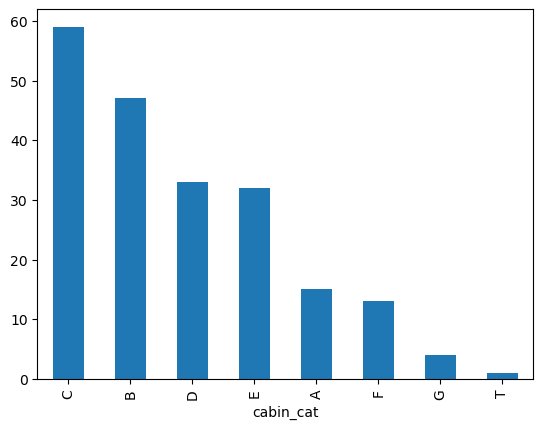

In [39]:
df['cabin_cat'].value_counts().plot(kind='bar')

In [20]:
#extract the last bit of ticket as number
df['ticket_num']=df['Ticket'].apply(lambda s:s.split()[-1])
df['ticket_num']=pd.to_numeric(df['ticket_num'],errors='coerce',downcast='integer')
df.head()

,Cabin,Ticket,number,Survived,number_numerical,cabin_num,cabin_cat,ticket_cat,ticket_num
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,A/5,21171.0
1,C85,PC 17599,3,1,3.0,85,C,PC,17599.0
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,STON/O2.,3101282.0
3,C123,113803,3,1,3.0,123,C,NaN,113803.0
4,NaN,373450,A,0,NaN,NaN,NaN,NaN,373450.0


In [24]:
# extract the first part of ticket as category
df['ticket_cat'] = df['Ticket'].apply(lambda s: s.split()[0])
df['ticket_cat'] = np.where(df['ticket_cat'].str.isdigit(), np.nan, df['ticket_cat'])
df.sample(20)

,Cabin,Ticket,number,Survived,number_numerical,cabin_num,cabin_cat,ticket_cat,ticket_num
100,NaN,349245,5,0,5.0,NaN,NaN,NaN,349245.0
799,NaN,345773,3,0,3.0,NaN,NaN,NaN,345773.0
130,NaN,349241,5,0,5.0,NaN,NaN,NaN,349241.0
666,NaN,234686,2,0,2.0,NaN,NaN,NaN,234686.0
203,NaN,2628,A,0,NaN,NaN,NaN,NaN,2628.0
392,NaN,3101277,1,0,1.0,NaN,NaN,NaN,3101277.0
211,NaN,F.C.C. 13528,3,1,3.0,NaN,NaN,F.C.C.,13528.0
602,NaN,113796,1,0,1.0,NaN,NaN,NaN,113796.0
20,NaN,239865,1,0,1.0,NaN,NaN,NaN,239865.0
360,NaN,347088,3,0,3.0,NaN,NaN,NaN,347088.0
